# Phân tích giá theo tháng, quý và cả năm



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
})
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


candidates = [
    Path('data/source/abc.csv'),
    Path('../data/source/abc.csv'),
    Path('/content/data/source/abc.csv'),
]
source_path = None
for candidate in candidates:
    if candidate.exists():
        source_path = candidate
        break
if source_path is None:
    raise FileNotFoundError('Không tìm thấy data/source/abc.csv')

df = pd.read_csv(source_path, parse_dates=['Date'])
df = df.sort_values('Date').reset_index(drop=True)
price_cols = ['Open', 'Price_2', 'Price_3', 'Price_4', 'Price_5', 'Price_6', 'Close']
df['High'] = df[price_cols].max(axis=1)
df['Low'] = df[price_cols].min(axis=1)
df['Range'] = df['High'] - df['Low']
df['Return_%'] = df['Close'].pct_change() * 100
df['Month'] = df['Date'].dt.month
df['Month_label'] = df['Date'].dt.strftime('%m/%Y')
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)

print(f'Khoảng thời gian: {df.Date.min():%d/%m/%Y} – {df.Date.max():%d/%m/%Y}')
print(f'Số ngày quan sát: {len(df):,}')
display(df.head())

Khoảng thời gian: 01/01/2024 – 30/12/2024
Số ngày quan sát: 365


,Date,Open,Price_2,Price_3,Price_4,Price_5,Price_6,Close,High,Low,Range,Return_%,Month,Month_label,Quarter
0,2024-01-01,"11,000.00","11,000.00","9,125.52","10,957.79","9,000.00","9,097.50","10,339.29","11,000.00","9,000.00","2,000.00",NaN,1,01/2024,2024Q1
1,2024-01-02,"11,026.94","9,987.00","11,373.22","11,049.58","9,901.65","9,794.51","9,613.51","11,373.22","9,613.51","1,759.70",-7.02,1,01/2024,2024Q1
2,2024-01-03,"10,276.29","9,902.07","8,684.92","8,652.16","8,773.22","8,856.02","10,343.03","10,343.03","8,652.16","1,690.87",7.59,1,01/2024,2024Q1
3,2024-01-04,"9,517.66","9,308.73","10,828.04","9,308.73","9,308.73","11,377.33","10,060.50","11,377.33","9,308.73","2,068.61",-2.73,1,01/2024,2024Q1
4,2024-01-05,"9,912.18","10,191.45","9,911.36","11,045.57","9,340.38","9,882.32","10,227.01","11,045.57","9,340.38","1,705.19",1.66,1,01/2024,2024Q1


## 1. Bảng giá trung bình và độ lệch chuẩn từng tháng

In [2]:
monthly = df.groupby(['Month', 'Month_label'], sort=True).agg(
    So_ngay=('Close', 'size'),
    Gia_tb=('Close', 'mean'),
    Do_lech_chuan=('Close', 'std'),
    Gia_thap_nhat=('Close', 'min'),
    Gia_cao_nhat=('Close', 'max'),
).reset_index()
monthly['Bien_do'] = monthly['Gia_cao_nhat'] - monthly['Gia_thap_nhat']
monthly['CV_%'] = monthly['Do_lech_chuan'] / monthly['Gia_tb'] * 100
monthly_table = monthly.rename(columns={
    'Month_label': 'Thang',
    'So_ngay': 'Số ngày',
    'Gia_tb': 'Giá trung bình',
    'Do_lech_chuan': 'Độ lệch chuẩn',
    'Gia_thap_nhat': 'Giá thấp nhất',
    'Gia_cao_nhat': 'Giá cao nhất',
    'Bien_do': 'Biên độ',
    'CV_%': 'CV (%)',
}).drop(columns='Month')
display(monthly_table)

,Thang,Số ngày,Giá trung bình,Độ lệch chuẩn,Giá thấp nhất,Giá cao nhất,Biên độ,CV (%)
0,01/2024,31,"10,187.38",668.80,"9,042.36","11,786.72","2,744.37",6.56
1,02/2024,29,"14,037.31","1,488.96","11,378.07","16,721.76","5,343.70",10.61
2,03/2024,31,"11,367.83","1,515.59","9,085.50","14,652.71","5,567.21",13.33
3,04/2024,30,"11,723.07","1,682.53","9,421.37","15,326.63","5,905.26",14.35
4,05/2024,31,"9,668.20","2,545.44","7,045.08","16,859.29","9,814.20",26.33
5,06/2024,30,"7,133.80",753.69,"5,995.58","8,886.91","2,891.33",10.56
6,07/2024,31,"6,206.70",925.21,"4,665.71","8,147.40","3,481.69",14.91
7,08/2024,31,"5,069.80",502.53,"4,073.88","5,999.25","1,925.38",9.91
8,09/2024,30,"3,538.67",477.75,"2,859.58","4,710.95","1,851.36",13.50
9,10/2024,31,"4,481.69",743.90,"3,126.27","5,709.89","2,583.62",16.60


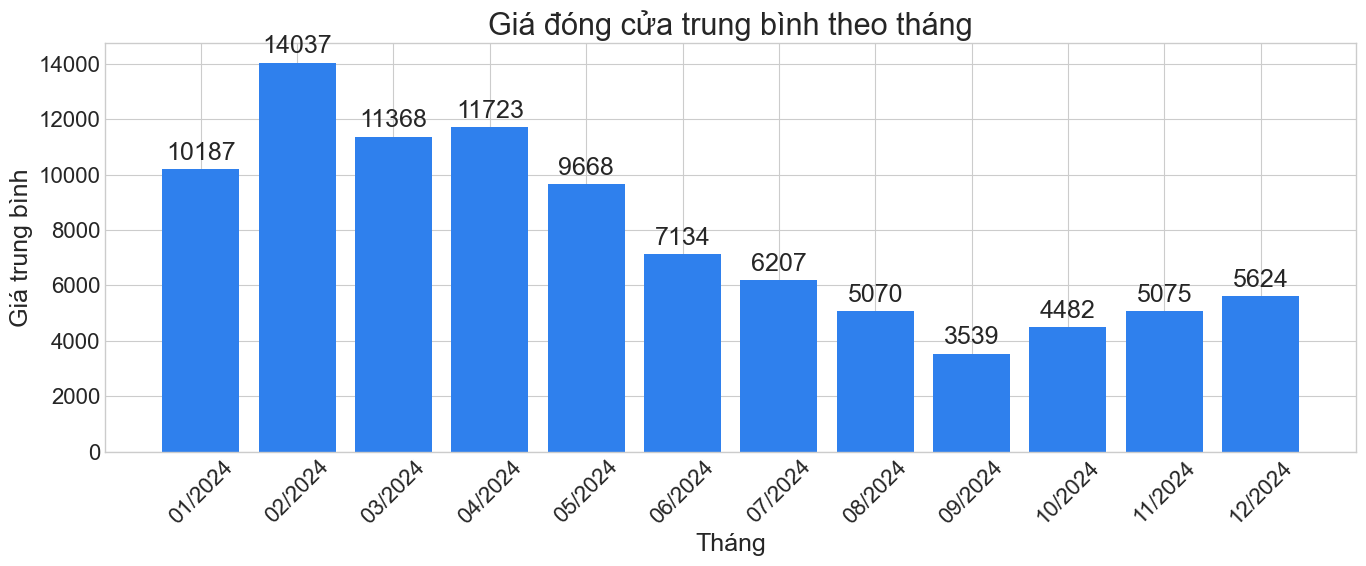

In [3]:
fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(monthly['Month_label'], monthly['Gia_tb'], color='#2f80ed')
ax.set_title('Giá đóng cửa trung bình theo tháng')
ax.set_xlabel('Tháng')
ax.set_ylabel('Giá trung bình')
ax.tick_params(axis='x', rotation=45)
ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=18)
plt.tight_layout()
plt.show()

## 2. Boxplot theo tháng

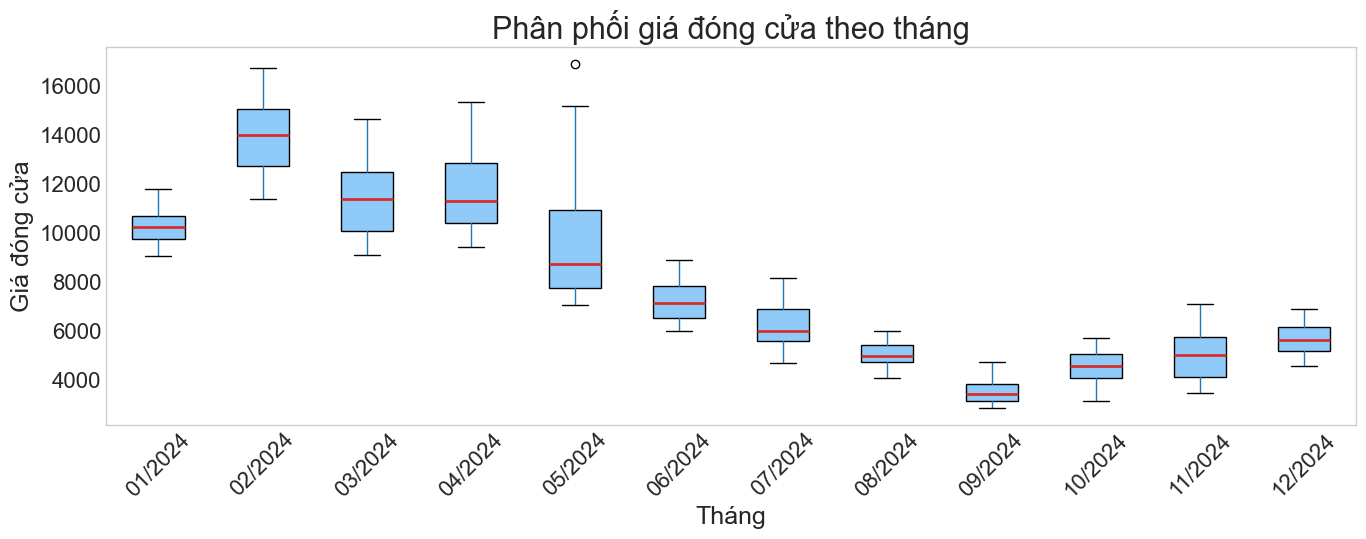

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))
df.boxplot(column='Close', by='Month_label', ax=ax, grid=False, patch_artist=True,
           boxprops=dict(facecolor='#90caf9'), medianprops=dict(color='#d32f2f', linewidth=2))
ax.set_title('Phân phối giá đóng cửa theo tháng')
ax.set_xlabel('Tháng')
ax.set_ylabel('Giá đóng cửa')
plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Tháng dao động mạnh nhất

In [5]:
max_std = monthly.loc[monthly['Do_lech_chuan'].idxmax()]
max_range_month = monthly.loc[monthly['Bien_do'].idxmax()]
print(f"Tháng có độ lệch chuẩn lớn nhất: {max_std['Month_label']} ({max_std['Do_lech_chuan']:,.2f}).")
print(f"Tháng có biên độ giá đóng cửa lớn nhất: {max_range_month['Month_label']} ({max_range_month['Bien_do']:,.2f}).")

Tháng có độ lệch chuẩn lớn nhất: 05/2024 (2,545.44).
Tháng có biên độ giá đóng cửa lớn nhất: 05/2024 (9,814.20).


## 4. Đánh giá theo quý

In [6]:
quarterly = df.groupby('Quarter').agg(
    So_ngay=('Close', 'size'),
    Gia_tb=('Close', 'mean'),
    Do_lech_chuan=('Close', 'std'),
    Gia_dau_quy=('Close', 'first'),
    Gia_cuoi_quy=('Close', 'last'),
    Gia_thap_nhat=('Close', 'min'),
    Gia_cao_nhat=('Close', 'max'),
).reset_index()
quarterly['Bien_do'] = quarterly['Gia_cao_nhat'] - quarterly['Gia_thap_nhat']
quarterly['Thay_doi_%'] = (quarterly['Gia_cuoi_quy']/quarterly['Gia_dau_quy']-1)*100
quarterly_table = quarterly.rename(columns={
    'Quarter': 'Quý',
    'So_ngay': 'Số ngày',
    'Gia_tb': 'Giá trung bình',
    'Do_lech_chuan': 'Độ lệch chuẩn',
    'Gia_dau_quy': 'Giá đầu quý',
    'Gia_cuoi_quy': 'Giá cuối quý',
    'Gia_thap_nhat': 'Giá thấp nhất',
    'Gia_cao_nhat': 'Giá cao nhất',
    'Bien_do': 'Biên độ',
    'Thay_doi_%': 'Thay đổi (%)',
})
display(quarterly_table)
best_q = quarterly.loc[quarterly['Thay_doi_%'].idxmax()]
worst_q = quarterly.loc[quarterly['Thay_doi_%'].idxmin()]
print(f"Quý tăng mạnh nhất: {best_q['Quarter']} ({best_q['Thay_doi_%']:.2f}%). Quý giảm mạnh nhất: {worst_q['Quarter']} ({worst_q['Thay_doi_%']:.2f}%).")

,Quý,Số ngày,Giá trung bình,Độ lệch chuẩn,Giá đầu quý,Giá cuối quý,Giá thấp nhất,Giá cao nhất,Biên độ,Thay đổi (%)
0,2024Q1,91,"11,816.41","2,043.82","10,339.29","9,878.08","9,042.36","16,721.76","7,679.41",-4.46
1,2024Q2,91,"9,510.11","2,603.51","10,773.25","7,925.84","5,995.58","16,859.29","10,863.71",-26.43
2,2024Q3,92,"4,953.60","1,279.74","7,514.49","3,306.95","2,859.58","8,147.40","5,287.82",-55.99
3,2024Q4,91,"5,053.88",928.91,"3,473.63","5,225.96","3,126.27","7,102.33","3,976.06",50.45


Quý tăng mạnh nhất: 2024Q4 (50.45%). Quý giảm mạnh nhất: 2024Q3 (-55.99%).


## 5. Bảng ngày bất thường

Giá tham chiếu của mỗi ngày là giá đóng cửa ngày liền trước; giá sàn và giá trần lần lượt bằng 90% và 110% giá tham chiếu. Bảng dưới đây liệt kê mọi giá giao dịch bằng một trong ba mức này.

In [7]:
prev_close = df['Close'].shift(1)
daily = df[['Date'] + price_cols].copy()
daily['Giá tham chiếu'] = prev_close
daily['Giá sàn'] = prev_close * 0.9
daily['Giá trần'] = prev_close * 1.1

transactions = daily.melt(
    id_vars=['Date', 'Giá tham chiếu', 'Giá sàn', 'Giá trần'],
    value_vars=price_cols,
    var_name='Cột giá',
    value_name='Giá giao dịch'
)
transactions = transactions[transactions['Giá tham chiếu'].notna()].copy()

is_floor = np.isclose(
    transactions['Giá giao dịch'], transactions['Giá sàn'],
    rtol=0, atol=1e-5, equal_nan=False
)
is_ceiling = np.isclose(
    transactions['Giá giao dịch'], transactions['Giá trần'],
    rtol=0, atol=1e-5, equal_nan=False
)
is_reference = np.isclose(
    transactions['Giá giao dịch'], transactions['Giá tham chiếu'],
    rtol=0, atol=1e-5, equal_nan=False
)

is_abnormal = is_floor | is_ceiling | is_reference
hit = transactions.loc[is_abnormal, [
    'Date', 'Cột giá', 'Giá giao dịch', 'Giá tham chiếu',
    'Giá sàn', 'Giá trần'
]].copy()
hit['Loại bất thường'] = np.select(
    [is_floor[is_abnormal], is_ceiling[is_abnormal], is_reference[is_abnormal]],
    ['Sàn', 'Trần', 'Tham chiếu'],
    default='Không xác định'
)
hit = hit.sort_values(['Date', 'Cột giá']).reset_index(drop=True)
display(hit)

,Date,Cột giá,Giá giao dịch,Giá tham chiếu,Giá sàn,Giá trần,Loại bất thường
0,2024-01-02,Price_3,"11,373.22","10,339.29","9,305.36","11,373.22",Trần
1,2024-01-03,Price_4,"8,652.16","9,613.51","8,652.16","10,574.86",Sàn
2,2024-01-04,Price_2,"9,308.73","10,343.03","9,308.73","11,377.33",Sàn
3,2024-01-04,Price_4,"9,308.73","10,343.03","9,308.73","11,377.33",Sàn
4,2024-01-04,Price_5,"9,308.73","10,343.03","9,308.73","11,377.33",Sàn
...,...,...,...,...,...,...,...
839,2024-12-29,Price_5,"5,571.86","6,190.95","5,571.86","6,810.05",Sàn
840,2024-12-30,Close,"5,225.96","5,806.62","5,225.96","6,387.28",Sàn
841,2024-12-30,Open,"6,387.28","5,806.62","5,225.96","6,387.28",Trần
842,2024-12-30,Price_2,"5,225.96","5,806.62","5,225.96","6,387.28",Sàn


## 6. Histogram hai quý đầu và hai quý cuối năm

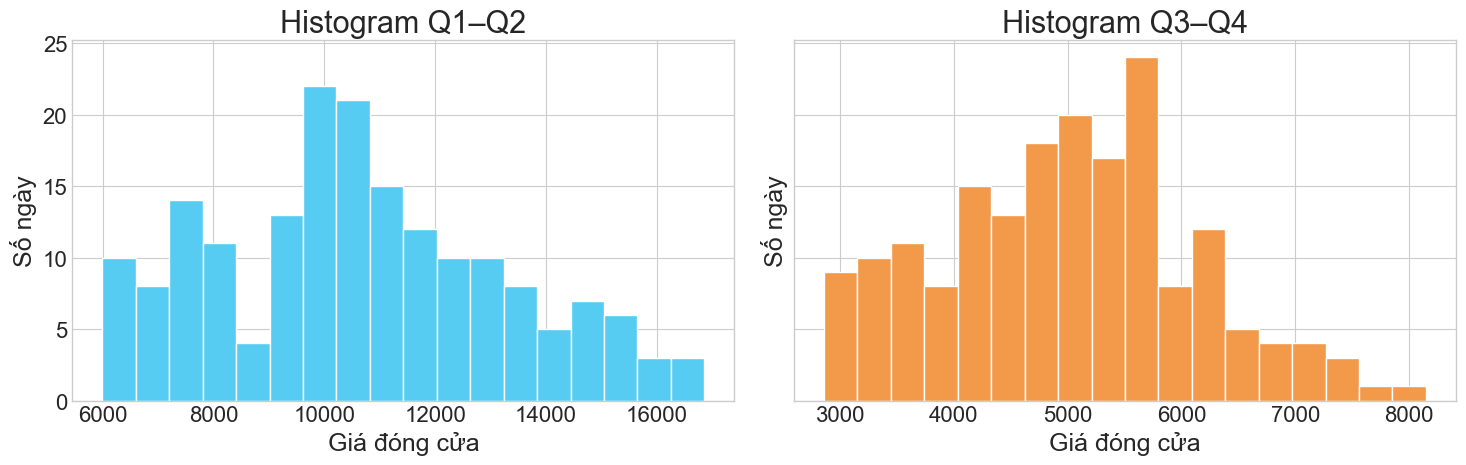

Giá trung bình Q1–Q2: 10,663.26; Q3–Q4: 5,003.47


In [8]:
first_half = df.loc[df['Date'].dt.quarter.isin([1, 2]), 'Close']
last_half = df.loc[df['Date'].dt.quarter.isin([3, 4]), 'Close']
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
axes[0].hist(first_half, bins=18, color='#56ccf2', edgecolor='white')
axes[0].set_title('Histogram Q1–Q2')
axes[1].hist(last_half, bins=18, color='#f2994a', edgecolor='white')
axes[1].set_title('Histogram Q3–Q4')
for axis in axes:
    axis.set_xlabel('Giá đóng cửa')
    axis.set_ylabel('Số ngày')
plt.tight_layout()
plt.show()
print(f'Giá trung bình Q1–Q2: {first_half.mean():,.2f}; Q3–Q4: {last_half.mean():,.2f}')

## 7. Xu hướng cả năm và biên độ lớn nhất

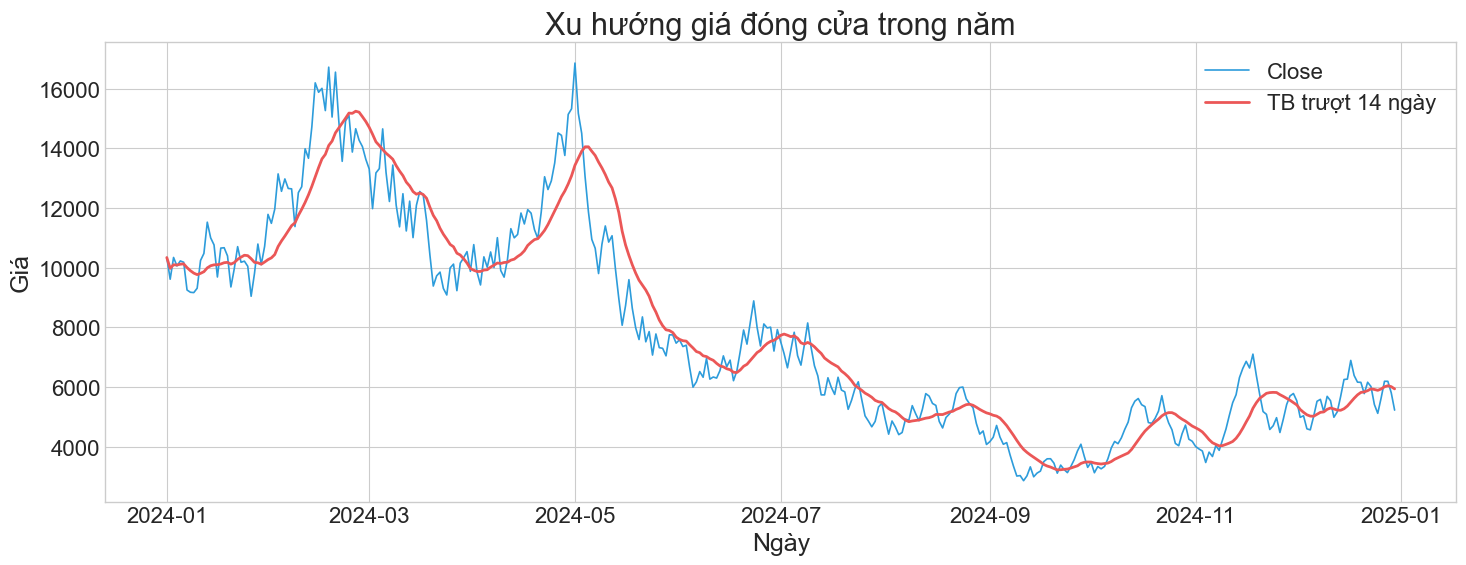

Thay đổi giá đóng cửa: giảm 49.46% so với đầu kỳ.
Biên độ trong ngày lớn nhất: 02/05/2024, High = 18,545.22, Low = 15,173.36, biên độ = 3,371.86.


In [9]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df['Date'], df['Close'], color='#2d9cdb', linewidth=1.2, label='Close')
ax.plot(df['Date'], df['Close'].rolling(14, min_periods=1).mean(), color='#eb5757', linewidth=2, label='TB trượt 14 ngày')
ax.set_title('Xu hướng giá đóng cửa trong năm')
ax.set_xlabel('Ngày')
ax.set_ylabel('Giá')
ax.legend()
plt.tight_layout()
plt.show()
first_close, last_close = df.iloc[0]['Close'], df.iloc[-1]['Close']
annual_change = (last_close/first_close-1)*100
if annual_change > 0:
    overall = 'tăng'
elif annual_change < 0:
    overall = 'giảm'
else:
    overall = 'đi ngang'
max_amp_day = df.loc[df['Range'].idxmax()]
print(f'Thay đổi giá đóng cửa: {overall} {abs(annual_change):.2f}% so với đầu kỳ.')
print(f"Biên độ trong ngày lớn nhất: {max_amp_day['Date']:%d/%m/%Y}, High = {max_amp_day['High']:,.2f}, Low = {max_amp_day['Low']:,.2f}, biên độ = {max_amp_day['Range']:,.2f}.")

## 8. Đường giá giảm và nến xanh

In [10]:
df['Line_down'] = df['Close'].diff() < 0
df['Green_candle'] = df['Close'] >= df['Open']
line_down = df['Line_down']
green_candle = df['Green_candle']
down_green = df[line_down & green_candle].copy()
print(f'Số ngày đường Close giảm nhưng nến xanh: {len(down_green)}')
display(down_green[['Date','Open','Close','Return_%']].head(10).rename(columns={'Date':'Ngày','Return_%':'Thay đổi (%)'}))

Số ngày đường Close giảm nhưng nến xanh: 61


,Ngày,Open,Close,Thay đổi (%)
3,2024-01-04,"9,517.66","10,060.50",-2.73
5,2024-01-06,"9,204.31","10,182.43",-0.44
7,2024-01-08,"8,326.18","9,175.94",-0.81
14,2024-01-15,"9,900.06","10,764.33",-2.14
24,2024-01-25,"9,866.56","10,047.06",-1.68
25,2024-01-26,"9,042.36","9,042.36",-10.00
28,2024-01-29,"9,713.48","10,103.09",-6.39
45,2024-02-15,"15,742.38","15,880.25",-1.95
49,2024-02-19,"15,049.59","15,049.59",-10.00
58,2024-02-28,"13,493.00","14,057.46",-1.53
